#### Догружаем модули и библиотеки

In [124]:
import sqlite3
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

#### Соединяемся с базой данных

In [125]:
con = sqlite3.connect('imdb_small_indexed.db')  # подключаемся
cur = con.cursor()  # создаём курсор

#### 1. Фильмы до 2018 года (я сделала невключительно, с выводом столцов названий и дат выхода, в порядке выхода)

In [126]:
before18 = """
SELECT title, premiered
FROM titles
WHERE premiered < 2018
ORDER BY premiered
"""

In [127]:
dfbefore18 = pd.read_sql_query(before18, con=con)
dfbefore18

,title,premiered
0,Miss Jerry,1894
1,Reproduction of the Corbett and Fitzsimmons Fight,1897
2,O Campo Grande,1898
3,O Carnaval em Lisboa,1898
4,Josephina Ruiz,1898
...,...,...
619812,Bacchanalia,2017
619813,Albatross,2017
619814,Aunty Donna: Best Content Ever!!1!,2017
619815,Illenau - die Geschichte einer ehemaligen Heil...,2017


#### 2. 50 самых популярных фильмов (по кол-ву оценок)

In [128]:
popular50 = """
SELECT title, votes
FROM titles
    JOIN rating ON titles.title_id = rating.title_id
ORDER BY votes DESC
LIMIT 50
"""

In [129]:
dfpopular50 = pd.read_sql_query(popular50, con=con)
dfpopular50

,title,votes
0,The Shawshank Redemption,2296829
1,The Dark Knight,2261286
2,Inception,2023295
3,Fight Club,1820822
4,Pulp Fiction,1793495
5,Forrest Gump,1769908
6,Game of Thrones,1717079
7,The Matrix,1644392
8,The Lord of the Rings: The Fellowship of the Ring,1630562
9,The Lord of the Rings: The Return of the King,1614816


#### 3. 10 самых популярных (по кол-ву оценок и с рейтингом >= 7) комедий 2019 года

In [130]:
comedies10 = """
SELECT title, votes, rating, premiered
FROM titles
    JOIN rating ON titles.title_id = rating.title_id
    JOIN film_genres ON titles.title_id = film_genres.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE genre_name = "Comedy" and premiered = 2019 and rating >= 7
ORDER BY votes DESC
LIMIT 10
"""

In [131]:
dfcomedies10 = pd.read_sql_query(comedies10, con=con)
dfcomedies10

,title,votes,rating,premiered
0,Once Upon a Time... In Hollywood,522128,7.6,2019
1,Parasite,494759,8.6,2019
2,Knives Out,404568,7.9,2019
3,Jojo Rabbit,268273,7.9,2019
4,Shazam!,244611,7.1,2019
5,Marriage Story,233135,8.0,2019
6,The Boys,201202,8.7,2019
7,The Gentlemen,196102,7.9,2019
8,Toy Story 4,193131,7.8,2019
9,Sex Education,145758,8.3,2019


#### 4. Год выхода и название фильмов с Вигго Мортенсеном

In [132]:
favactor = """
SELECT premiered, title
FROM titles
    JOIN crew ON titles.title_id = crew.title_id
    JOIN people ON crew.person_id = people.person_id
WHERE name = "Viggo Mortensen"
ORDER BY premiered
"""

In [133]:
dffavactor = pd.read_sql_query(favactor, con=con)
dffavactor

,premiered,title
0,NaN,Untitled Skydance Project
1,NaN,Eureka
2,NaN,The Horsecatcher
3,NaN,Unabomb
4,1987.0,Salvation!: Have You Said Your Prayers Today?
5,1987.0,Prison
6,1990.0,The Reflecting Skin
7,1991.0,The Indian Runner
8,1992.0,Ruby Cairo
9,1993.0,Boiling Point


#### 5. Количество документальных фильмов по годам

In [279]:
documentaries = """
SELECT premiered as Year, COUNT(titles.title_id) as Num_of_documentaries -- cчитаем по сгруппированному число фильмов
FROM titles
    JOIN film_genres ON titles.title_id = film_genres.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE genre_name = "Documentary"
GROUP BY premiered
ORDER BY premiered DESC
"""

In [280]:
dfdocumentaries = pd.read_sql_query(documentaries, con=con)
dfdocumentaries

,Year,Num_of_documentaries
0,2027.0,2
1,2023.0,2
2,2022.0,51
3,2021.0,551
4,2020.0,4788
...,...,...
124,1900.0,4
125,1899.0,8
126,1898.0,8
127,1897.0,1


#### 6.1. Найдите актеров-долгожителей: топ-10 по возрасту

In [283]:
age10_query = """
SELECT DISTINCT name, SUM(2023 - born) OVER(PARTITION by person_id) as Age -- стараемся разделять разных людей при подсчёте
FROM people
WHERE born IS NOT NULL and died IS NULL -- мы хотим найти тех, кто еще не умер! но уже родился
ORDER BY Age DESC
LIMIT 10
"""

In [285]:
df_age10 = pd.read_sql_query(age10_query, con=con)  # в датабазе бывают странно заполнены данные, поэтому результаты тоже странные
df_age10

,name,Age
0,Paul Walsh,2002
1,Koray Gelisen,956
2,William S. Hooser,187
3,Vilmos Radó,176
4,California Truman,174
5,Louis Hahn,173
6,André Sylvane,173
7,Charles Dungan,170
8,Edmond Duquesne,169
9,Maurice Ordonneau,169


#### 6.2. Найдите актеров-долгожителей: список тех, кто дожил до 100 лет и более

In [286]:
longlivers_query = """
SELECT DISTINCT name, born, died
FROM people
WHERE (died IS NOT NULL and died - born >= 100) or (died IS NULL and 2023 - born >= 100)  -- а тут считаем уже и мёртвых, и живых
"""

In [287]:
df_longlivers = pd.read_sql_query(longlivers_query, con=con)
df_longlivers

,name,born,died
0,'Double Duty' Radcliffe,1902,2005.0
1,A. Barr-Smith,1905,NaN
2,A. Culp,1886,NaN
3,A. Hyatt Verrill,1871,NaN
4,A. Karunanidhi,1923,NaN
...,...,...,...
3987,Édouard Pinto,1887,NaN
3988,Élio Vieira de Araújo,1919,NaN
3989,Éva Gyulányi,1915,2018.0
3990,Íñigo de Martino,1905,2006.0


#### 7, 8. Распределение оценок (округленных до ближайшего целого) для комедий и для документальных фильмов

In [142]:
comsanddocs = """
SELECT DISTINCT title, genre_name, ROUND(rating) as rating
FROM titles
    JOIN rating ON titles.title_id = rating.title_id
    JOIN film_genres ON rating.title_id = film_genres.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE genre_name = "Documentary" or genre_name = "Comedy"
"""

In [143]:
df_comsanddocs = pd.read_sql_query(comsanddocs, con=con)
df_comsanddocs

,title,genre_name,rating
0,Salome Mad,Comedy,4.0
1,Life of Villa,Documentary,7.0
2,Dr. Mawson in the Antarctic,Documentary,6.0
3,My Husband's Getting Married,Comedy,4.0
4,Die Insel der Seligen,Comedy,5.0
...,...,...,...
132211,The Khatra Show,Comedy,7.0
132212,Nuestra película,Documentary,7.0
132213,The Mystery of a Buryat Lama,Documentary,4.0
132214,Drømmeland,Documentary,7.0


In [288]:
countcoms = dict(Counter(df_comsanddocs.loc[df_comsanddocs["genre_name"] == "Comedy"]["rating"]))   # считаем количество оценок для разных жанров по рейтингу
countdocs = dict(Counter(df_comsanddocs.loc[df_comsanddocs["genre_name"] == "Documentary"]["rating"]))
print(countcoms, countdocs)

{4.0: 6478, 5.0: 14403, 6.0: 24731, 7.0: 23763, 8.0: 12142, 3.0: 2476, 1.0: 138, 2.0: 717, 9.0: 1887, 10.0: 96} {7.0: 16122, 6.0: 5972, 8.0: 15227, 9.0: 5057, 4.0: 643, 5.0: 1720, 1.0: 34, 2.0: 115, 3.0: 282, 10.0: 213}


In [289]:
counts = []  # 
for x in countcoms:
    counts.append([x, countcoms[x], countdocs[x]])
counts

[[4.0, 6478, 643],
 [5.0, 14403, 1720],
 [6.0, 24731, 5972],
 [7.0, 23763, 16122],
 [8.0, 12142, 15227],
 [3.0, 2476, 282],
 [1.0, 138, 34],
 [2.0, 717, 115],
 [9.0, 1887, 5057],
 [10.0, 96, 213]]

In [290]:
df_counts = pd.DataFrame(counts, columns = ["rating", "votes for comedies", "votes for documentaries"])  # делаем удобную таблицу для визуализации
df_counts = df_counts.sort_values(by="rating").reset_index(drop=True)  # а еще хочется, чтобы она была по рейтингу от меньшего к большему
df_counts

,rating,votes for comedies,votes for documentaries
0,1.0,138,34
1,2.0,717,115
2,3.0,2476,282
3,4.0,6478,643
4,5.0,14403,1720
5,6.0,24731,5972
6,7.0,23763,16122
7,8.0,12142,15227
8,9.0,1887,5057
9,10.0,96,213


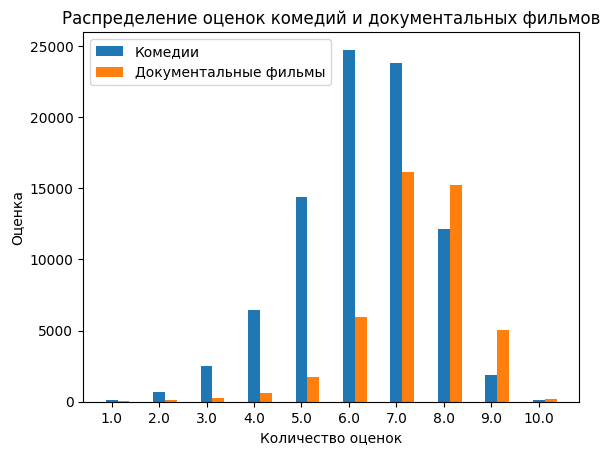

In [291]:
axisX = np.arange(10)  # визуализируем: делаем столбчатую диаграмму по рейтингу по оси Х и оценкам по Y
plt.bar(axisX, df_counts["votes for comedies"], width = 0.25)
plt.bar(axisX + 0.25, df_counts["votes for documentaries"], width = 0.25)  # сдвигаем один жанр, чтобы комедии и документалки красивенько стояли рядом
plt.xticks(ticks = axisX, labels = df_counts["rating"])
plt.title('Распределение оценок комедий и документальных фильмов')
plt.ylabel('Оценка')
plt.xlabel('Количество оценок')
plt.legend(labels=['Комедии', 'Документальные фильмы'])
plt.show()

#### 8. Пункт 6 в отдельных таблицах

Везде порядок одинаковый: создаём таблицу, затем вписываем в нее результат шестого пункта.

In [292]:
cur.execute("""CREATE TABLE age10 (name TEXT, age INT)""")

OperationalError: table age10 already exists

In [293]:
con.commit()

In [294]:
cur.execute("""
SELECT DISTINCT name, SUM(2023 - born) OVER(PARTITION by person_id) AS Age
FROM people
WHERE born IS NOT NULL and died IS NULL
ORDER BY Age DESC
LIMIT 10
""")
data_age10 = cur.fetchall()
data_age10

[('Paul Walsh', 2002),
 ('Koray Gelisen', 956),
 ('William S. Hooser', 187),
 ('Vilmos Radó', 176),
 ('California Truman', 174),
 ('Louis Hahn', 173),
 ('André Sylvane', 173),
 ('Charles Dungan', 170),
 ('Edmond Duquesne', 169),
 ('Maurice Ordonneau', 169)]

In [295]:
cur.executemany("INSERT INTO age10 VALUES (?, ?)", data_age10)
con.commit()

In [296]:
cur.execute("""CREATE TABLE longlivers (name TEXT, born INT, died INT)""")

OperationalError: table longlivers already exists

In [297]:
cur.execute("""
SELECT DISTINCT name, born, died
FROM people
WHERE (died IS NOT NULL and died - born >= 100) or (died IS NULL and 2023 - born >= 100)
""")
data_longlivers = cur.fetchall()
data_longlivers

[("'Double Duty' Radcliffe", 1902, 2005),
 ('A. Barr-Smith', 1905, None),
 ('A. Culp', 1886, None),
 ('A. Hyatt Verrill', 1871, None),
 ('A. Karunanidhi', 1923, None),
 ('A. Lloyd Lewis', 1877, None),
 ('A. Van Buren Powell', 1886, None),
 ('A.E. Hotchner', 1917, 2020),
 ('A.K. Kamalan', 1921, None),
 ('A.S.A. Sami', 1915, None),
 ('A.V. Curtice', 1896, None),
 ('Aadu Hint', 1910, None),
 ('Aage Jessen', 1914, None),
 ('Abbé Père Aimé Duval', 1918, None),
 ('Abdolhossein Sepenta', 1901, None),
 ('Abel Jores', 1923, None),
 ('Achiles Tartari', 1901, None),
 ('Ada Pellová-Czivisová', 1897, None),
 ('Ada Van Roon', 1882, None),
 ('Addi Adametz', 1923, None),
 ('Adele Clifton', 1892, None),
 ('Adelheid Wette', 1858, None),
 ('Adelina Campos', 1905, 2008),
 ('Adolf Hultgran', 1887, None),
 ('Adolf Lantz', 1882, None),
 ('Adolf Schlasy', 1896, None),
 ('Adolf Trotz', 1895, None),
 ('Adolf Weisse', 1855, None),
 ('Adolph Fink', 1873, None),
 ('Adolph Zukor', 1873, 1976),
 ('Adriana Costamagna

In [298]:
con.commit()

In [252]:
cur.executemany("INSERT INTO longlivers VALUES (?, ?, ?)", data_longlivers)
con.commit()

## Задание на 8.

+ #### Доля женщин и мужчин в фильмах такого-то жанра такого-то года

In [299]:
women = """
SELECT titles.title_id AS id, title, premiered, genre_name, 
    CAST(COUNT(DISTINCT CASE 
                    WHEN category = 2 THEN person_id -- мы хотим посчитать всех актрис, а затем поделить на общую сумму актрис и актёров, для этого
                    END) AS FLOAT) /                 -- используем условия
        (COUNT(DISTINCT CASE 
                    WHEN category = 1 THEN person_id 
                    END) 
                + COUNT(DISTINCT CASE 
                    WHEN category = 2 THEN person_id 
                    END)) AS how_many_actresses,
                    
    CAST(COUNT(DISTINCT CASE 
                    WHEN category = 1 THEN person_id -- затем делаем то же самое, но с актёрами
                    END) AS FLOAT) / 
        (COUNT(DISTINCT CASE 
                    WHEN category = 1 THEN person_id 
                    END) 
                + COUNT(DISTINCT CASE 
                    WHEN category = 2 THEN person_id 
                    END)) AS how_many_actors
FROM titles
    JOIN film_genres ON titles.title_id = film_genres.title_id
    JOIN crew ON titles.title_id = crew.title_id
    JOIN genre_types ON film_genres.genre_id = genre_types.id
WHERE category IN (1, 2, 3)
GROUP BY titles.title_id, title, premiered, genre_name
"""

In [300]:
df_women = pd.read_sql_query(women, con=con)  # всё скидываем в датафрейм, он нам пригодится для сводной таблицы
df_women

,id,title,premiered,genre_name,how_many_actresses,how_many_actors
0,9,Miss Jerry,1894.0,Romance,0.333333,0.666667
1,335,Soldiers of the Cross,1900.0,Biography,0.166667,0.833333
2,335,Soldiers of the Cross,1900.0,Drama,0.166667,0.833333
3,574,The Story of the Kelly Gang,1906.0,Biography,0.500000,0.500000
4,574,The Story of the Kelly Gang,1906.0,Crime,0.500000,0.500000
...,...,...,...,...,...,...
775034,13333446,The Mountain Have No Words,2005.0,Drama,0.333333,0.666667
775035,13333504,Dared My Best Friend to Ruin My Life,2020.0,Mystery,0.750000,0.250000
775036,13333616,Spiral Drive,2020.0,Comedy,0.000000,1.000000
775037,13333616,Spiral Drive,2020.0,Horror,0.000000,1.000000


+ #### Сводная таблица по жанрам и годам

In [301]:
# делаем сводную таблицу, где в строках у нас жанры, в столбцах -- года, а в ячейках среднее (дефолтное) аггрегированное значение доли
# вместо нанов ставим нули
pivtab = pd.pivot_table(df_women, index = "genre_name", columns = "premiered", values = "how_many_actresses", fill_value = 0)
pivtab.to_csv("pivot_table.csv")
pivtab

premiered,1894.0,1900.0,1902.0,1903.0,1906.0,1907.0,1908.0,1909.0,1910.0,1911.0,...,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0,2027.0,2028.0
genre_name,,,,,,,,,,,,,,,,,,,,,
Action,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.307927,0.311162,0.310664,0.293034,0.442593,0.463333,0.000000,0.750,0.0,0.444444
Adult,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.599978,0.484662,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.0,0.000000
Adventure,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.250000,0.750000,0.250000,...,0.334056,0.362870,0.393117,0.303605,0.300000,0.625000,0.500000,0.750,0.0,0.444444
Animation,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.397902,0.382501,0.451395,0.258333,0.400000,0.000000,0.000000,0.000,0.0,0.000000
Biography,0.000000,0.166667,0.0,0.5,0.500000,0.000000,0.0,0.400000,0.250000,0.250000,...,0.292794,0.359494,0.318651,0.250000,0.875000,0.000000,0.500000,0.000,0.0,0.000000
Comedy,0.000000,0.000000,0.0,0.0,0.666667,1.000000,0.0,0.525000,0.281250,0.217262,...,0.393739,0.388345,0.387198,0.420088,0.408333,0.500000,0.000000,0.000,0.0,0.000000
Crime,0.000000,0.000000,0.0,0.0,0.500000,0.000000,0.0,0.000000,0.062500,0.500000,...,0.334295,0.320311,0.317404,0.160455,0.275000,0.000000,0.000000,0.000,0.0,0.000000
Documentary,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,...,0.263897,0.280701,0.252144,0.458333,0.750000,0.000000,0.000000,0.000,0.0,0.000000
Drama,0.000000,0.166667,1.0,0.5,0.500000,0.222222,0.5,0.534375,0.203288,0.320011,...,0.404028,0.411550,0.395228,0.314672,0.335714,0.248299,0.666667,0.000,0.0,0.444444


+ #### Наблюдаемые тенденции и визуализация
Информации очень много и тенденций по общей таблице (которую я как раз для общего рассмотрения и сохранила в отдельный csv) тоже можно усмотреть довольно немало. Данных примерно по всем фильмам из самого раннего и самого позднего периодов в датабазе меньше всего, и они самые хаотичные, поэтому их стоит рассматривать осторожно (например, там просто не такой большой список известных актеров). Можно приметить, что жанр романтического кино -- самый ранний, в котором в списке актёров (видимо, основных) числятся женщины, а так же он стабильно держит планку женщин на главных ролях около 50%, одном из самых высоких уровней вообще. Вторыми по возникновению числятся драма и биографическое кино. Но при этом в биографиях количество женщин-актёров будто бы гораздо сильнее меняется от года к году, чем в драмах или в романтике. Но в целом романтика стабильно держит планку популярности женщин в кастах, биографическое кино довольно низко по этому значению, а драма выше биографий, но ниже романтики, при этом число женщин стабильно на уровне примерно 40%.
В целом, количество женщин-актрис в кино сильно меньше, чем мужчин-актёров.
Ниже продемонстрировано изменение доли актрис в фильмах по годам: разные линии -- разные жанры.

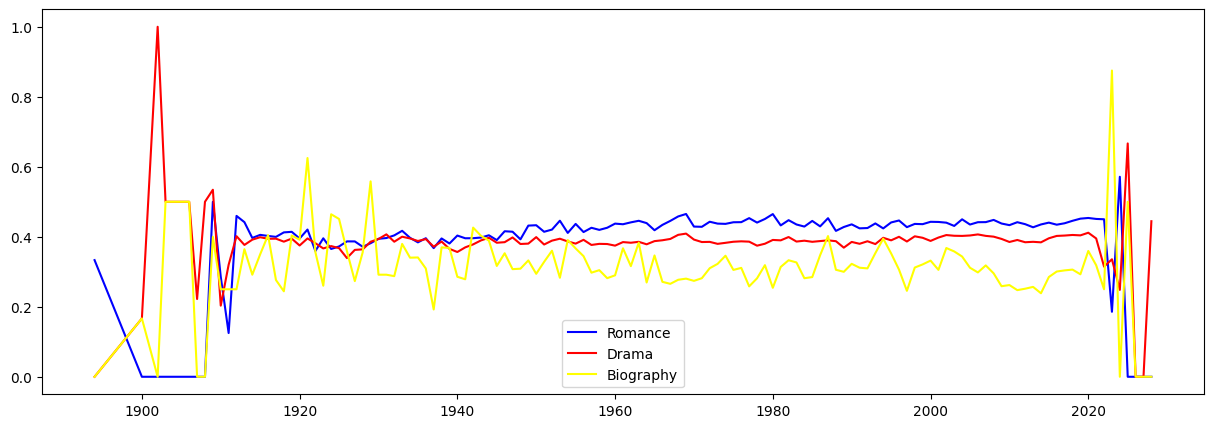

In [276]:
plt.figure(figsize = (15,5))
plt.plot(pivtab.loc["Romance"], color = "blue", label = "Romance")
plt.plot(pivtab.loc["Drama"], color = "red", label = "Drama")
plt.plot(pivtab.loc["Biography"], color = "yellow", label = "Biography")
plt.legend()

Выводы трудно сделать по такому объему данных, но хочется отметить, что в целом процент женщин в жанрах, которые в принципе были популярны на протяжение всего периода активного существования киноиндустрии, не особенно отклонялся от значения "ниже среднего". Наверняка есть ещё тенденции, связанные с тем, что какие-то жанры стали популярнее позже, чем другие: например, появилось гораздо больше фэнтэзи и фантастики с развитием компьютерной графики.

## Задание на 9-10.

**Пусть у нас будет социолингвистическая база языков некоторого ареала**. Нам захочется в ней иметь:
- данные о самих языках:
    + айди
    + название
    + генеалогический статус: например, каждый язык относится к какой-то ветви какой-то группы языков
    + количество носителей
    + статус (вымерший, под угрозой вымирания, уязвимый, живой и т.д.)
    + точное место распространения
    + исследователи языка, к которым можно обратиться за дополнительной информацией
- данные о генеалогии -- ветви:
    + какие языки к каким ветвиям принадлежат
    + какие бывают ветви
    + к каким группам они относятся
- данные о генеалогии -- группы:
    + айди
    + какие они бывают
- данные о типах:
    + какие бывают
    + список языков по типам
    + связаны ли с генеалогией (пиджины и креолы должны добавлять еще дополнительные значения к генеалогическому статусу)
- данные о статусах:
    + список языков по статусам
    + какие они бывают
- данные об исследователях:
    + айди
    + ФИО
    + страна рождения
    + дата рождения
    + дата смерти
    + аффилиация
    + электронная почта

Тогда мы сможем оперативно получать информацию о языке и получать список языков, которые относятся к определённому типу, ветви генеалогического дерева.

Картинка будет лежать в репозитории -- database.jpg